In [1]:
import sys
sys.path.append("..")   # lets the notebook find the src folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import load_split, load_activity_labels

sns.set_theme()

In [9]:
X_train, y_train, s_train = load_split("train")
labels = load_activity_labels()
y_names = y_train.map(labels).rename("activity")

In [10]:
print("Shape:", X_train.shape)
print("Missing values:", X_train.isna().sum().sum())
print("Duplicate rows:", X_train.duplicated().sum())
print("Constant columns:", (X_train.nunique() == 1).sum())
print("Data types:", X_train.dtypes.value_counts().to_dict())
print("Min value:", X_train.min().min(), "| Max value:", X_train.max().max())

Shape: (7352, 561)
Missing values: 0
Duplicate rows: 0
Constant columns: 0
Data types: {dtype('float64'): 561}
Min value: -1.0 | Max value: 1.0


activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64
activity
LAYING                19.1
STANDING              18.7
SITTING               17.5
WALKING               16.7
WALKING_UPSTAIRS      14.6
WALKING_DOWNSTAIRS    13.4
Name: count, dtype: float64


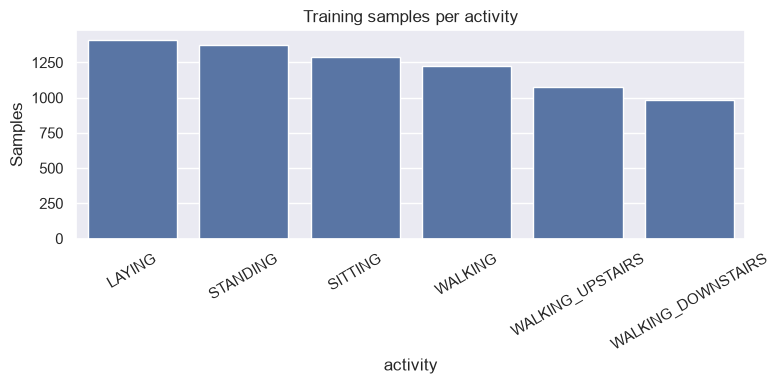

In [11]:
counts = y_names.value_counts()
print(counts)
print((counts / len(y_names) * 100).round(1))

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.xticks(rotation=30)
plt.title("Training samples per activity")
plt.ylabel("Samples")
plt.tight_layout()
plt.savefig("../reports/figures/class_balance.png", dpi=150)
plt.show()

In [12]:
per_subject = s_train.value_counts().sort_index()
print(per_subject.describe())

count     21.000000
mean     350.095238
std       35.603237
min      281.000000
25%      323.000000
50%      347.000000
75%      376.000000
max      409.000000
Name: count, dtype: float64


In [13]:
names = pd.Series(X_train.columns)
print("Time-domain (start with 't'):", names.str.startswith("t").sum())
print("Frequency-domain (start with 'f'):", names.str.startswith("f").sum())
print("Names containing 'Acc':", names.str.contains("Acc").sum())
print("Names containing 'Gyro':", names.str.contains("Gyro").sum())

Time-domain (start with 't'): 265
Frequency-domain (start with 'f'): 289
Names containing 'Acc': 345
Names containing 'Gyro': 213


In [14]:
corr = X_train.corr().abs()                                  # |correlation| between every pair of features
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # keep each pair once

for threshold in [0.99, 0.95, 0.90]:
    mask = upper > threshold
    print(f"|r| > {threshold}: {mask.sum().sum()} pairs, "
          f"{mask.any().sum()} features removable (each has a more-correlated earlier partner)")

|r| > 0.99: 207 pairs, 122 features removable (each has a more-correlated earlier partner)
|r| > 0.95: 2281 pairs, 308 features removable (each has a more-correlated earlier partner)
|r| > 0.9: 8206 pairs, 359 features removable (each has a more-correlated earlier partner)


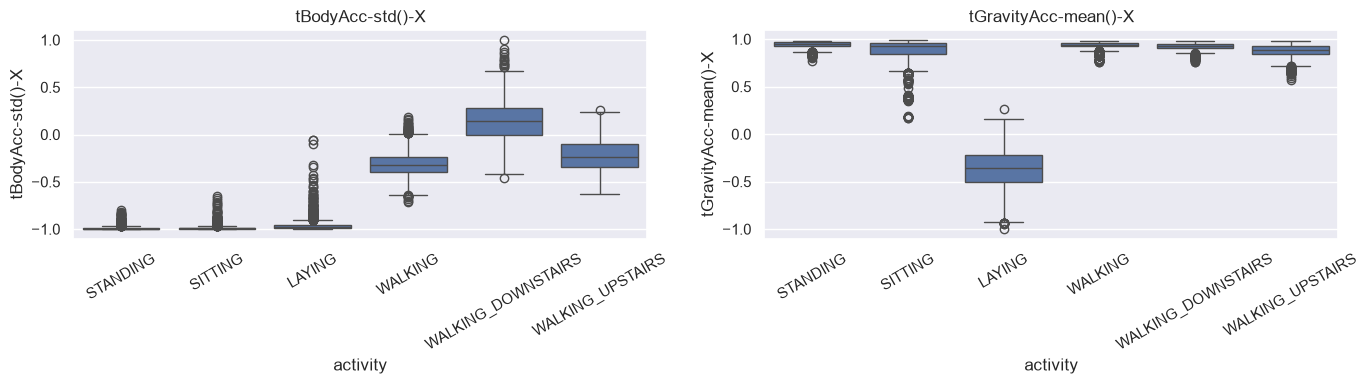

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, feature in zip(axes, ["tBodyAcc-std()-X", "tGravityAcc-mean()-X"]):
    sns.boxplot(x=y_names, y=X_train[feature], ax=ax)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../reports/figures/feature_by_activity.png", dpi=150)
plt.show()